# 05 — Learning together: auxiliary-task synergy vs interference

**Question.** Train two tasks jointly on one shared trunk and they can help
each other — or fight, dragging the shared representation in incompatible
directions. What decides which happens? Spoiler from the results below:
*not* whether the tasks sound related. What matters is whether they demand
compatible features — and gradient alignment on the trunk is the measurable
proxy for that.

**What the literature says.**
- Multi-task learning works when the auxiliary task supplies a compatible
  inductive bias, and the effect is largest when the main task is
  label-starved (Caruana 1997; Ruder 2017 is the modern survey).
- Which pairs actually help is an empirical question. Standley et al.
  (ICML 2020) trained every pairing of five vision tasks and found both
  synergies and consistent interference, with no simple semantic rule
  predicting which — task affinity has to be measured.
- The standard *diagnostic* is gradient conflict on the shared parameters:
  when the tasks' loss gradients point in incompatible directions, joint
  training hurts. PCGrad (Yu et al., NeurIPS 2020) is built entirely
  around detecting and projecting away that conflict.

**Setup.** The main task is deliberately label-starved — **100 labeled
MNIST digits**. Three auxiliaries, every one at the same loss weight (1.0):

| auxiliary | sounds like | what it actually demands from the trunk |
|---|---|---|
| digits 5–9, 10k labeled | related | the same stroke/shape features as the main task |
| rotation prediction, 10k images | related (same images, "free" labels) | orientation-*sensitive* features — while digit identity wants orientation-*normalized* ones |
| shuffled labels on the main 100 images | adversarial | a contradictory answer per image — but only 100 of them |

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tllab").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import torch

import tllab
from tllab import analysis, data, models, train

tllab.setup()

tllab: torch 2.13.0+cu130 | threads=4 | QUICK=False | root=/home/user/transfer-learning-lab


## The experiment

All conditions: Adam lr 1e-3, batch 32, 40 epochs, 3 seeds.
`train.fit_multitask` builds a fresh two-head net (shared encoder, one
linear head per task), takes one batch from *every* task per step and sums
the losses; steps per epoch follow the digits task, so every condition sees
the same number of digit batches. Every 5 steps it logs the cosine
similarity between the two tasks' loss gradients on the shared trunk; we
keep the seed-0 traces for the diagnostic figure (accuracy rows and traces
share one cache file so they can never go out of sync).

In [2]:
N_MAIN = tllab.q(100, 50)          # labeled digits for the main task
N_AUX = tllab.q(10_000, 1_000)     # images for each large auxiliary
EPOCHS = tllab.q(40, 4)
BATCH = 32
GRAD_LOG_EVERY = 5
CONDITIONS = ["single", "+digits 5-9 aux", "+rotation aux",
              "+contradictory labels"]


def mtl_sweep() -> pd.DataFrame:
    rows = []
    for seed in tllab.seeds():
        main = data.subset(data.get_task("mnist"), N_MAIN, seed)

        model = models.new_cnn(10, seed)
        acc_a = train.fit(model, main, epochs=EPOCHS, batch_size=BATCH,
                          seed=seed, eval_every=10).final_acc

        # (b) related supervised auxiliary: disjoint digit classes, 10k
        aux_rel = data.subset(data.get_task("mnist:5-9"), N_AUX, seed + 50)
        res_b, grad_b = train.fit_multitask(
            {"digits": main, "digits59": aux_rel}, main="digits",
            epochs=EPOCHS, batch_size=BATCH, seed=seed,
            grad_log_every=GRAD_LOG_EVERY)

        # (c) self-supervised rotation auxiliary on 10k images
        aux_rot = data.subset(data.get_task("mnist:rotpred"), N_AUX, seed + 50)
        res_c, grad_c = train.fit_multitask(
            {"digits": main, "rotpred": aux_rot}, main="digits",
            epochs=EPOCHS, batch_size=BATCH, seed=seed,
            grad_log_every=GRAD_LOG_EVERY)

        # (d) contradictory labels on the SAME 100 images
        g = torch.Generator().manual_seed(seed + 99)
        conflict = data.Task(
            "randlabel-same-images", 10, main.train_x,
            main.train_y[torch.randperm(len(main.train_y), generator=g)],
            main.test_x, main.test_y)
        res_d, grad_d = train.fit_multitask(
            {"digits": main, "conflict": conflict}, main="digits",
            epochs=EPOCHS, batch_size=BATCH, seed=seed,
            grad_log_every=GRAD_LOG_EVERY)

        for cond, acc in [("single", acc_a),
                          ("+digits 5-9 aux", res_b.final_acc),
                          ("+rotation aux", res_c.final_acc),
                          ("+contradictory labels", res_d.final_acc)]:
            rows.append({"record": "acc", "condition": cond, "seed": seed,
                         "acc": acc, "step": None, "cos": None})
        print(f"  seed={seed}: single={acc_a:.3f} +5-9={res_b.final_acc:.3f} "
              f"+rot={res_c.final_acc:.3f} +conflict={res_d.final_acc:.3f}")

        if seed == 0:  # keep grad-cosine traces for the diagnostic figure
            for cond, gdf in [("+digits 5-9 aux", grad_b),
                              ("+rotation aux", grad_c),
                              ("+contradictory labels", grad_d)]:
                for _, r in gdf.iterrows():
                    rows.append({"record": "grad_cos", "condition": cond,
                                 "seed": seed, "acc": None,
                                 "step": int(r["step"]), "cos": float(r["cos"])})
    return pd.DataFrame(rows)


df = train.cached_sweep("05_mtl", mtl_sweep)
acc_df = df[df["record"] == "acc"]
grad_df = df[df["record"] == "grad_cos"].copy()
acc_df.groupby("condition")["acc"].agg(["mean", "min", "max"]).reindex(CONDITIONS)

[sweep cached] 05_mtl.csv


,mean,min,max
condition,,,
single,0.845400,0.8281,0.8571
+digits 5-9 aux,0.858133,0.8141,0.9008
+rotation aux,0.782300,0.7347,0.8101
+contradictory labels,0.839500,0.8097,0.8748


figure -> artifacts/figures/05_mtl_bars.png


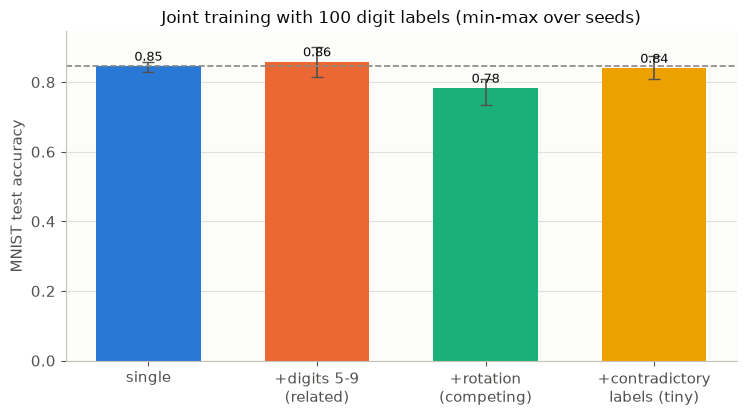

In [3]:
g = acc_df.groupby("condition")["acc"]
means = [g.mean()[c] for c in CONDITIONS]
spreads = [(g.min()[c], g.max()[c]) for c in CONDITIONS]
plt.figure(figsize=(7.6, 4.3))
analysis.plot_bars(["single", "+digits 5-9\n(related)", "+rotation\n(competing)",
                    "+contradictory\nlabels (tiny)"], means, spreads,
                   ylabel="MNIST test accuracy",
                   title=f"Joint training with {N_MAIN} digit labels "
                         "(min-max over seeds)",
                   baseline=means[0], baseline_label="single-task mean")
analysis.savefig("05_mtl_bars")

## The diagnostic: gradient alignment on the shared trunk

The bars say *what* happened; the trunk gradient cosine says *why*. The
cosine is measured on the **shared encoder only**, so it asks a precise
question: do the two tasks push the *features* in compatible directions?
(In ~196k dimensions even compatible gradients are nearly orthogonal, so
read *small positive vs near zero*, not cosines near 1.)

That framing predicts something counterintuitive about the contradictory-
labels arm: its trace should be the *most* aligned, not the least. Both
heads look at the identical 100 images, so both push the trunk toward
better features **of those images** — the contradiction lives entirely in
the heads, which is exactly why the trunk absorbs it. The genuinely
dangerous auxiliary is the one whose *feature* demands compete — rotation
— and it shows up as the lowest, occasionally negative, trace.

figure -> artifacts/figures/05_grad_cosine.png


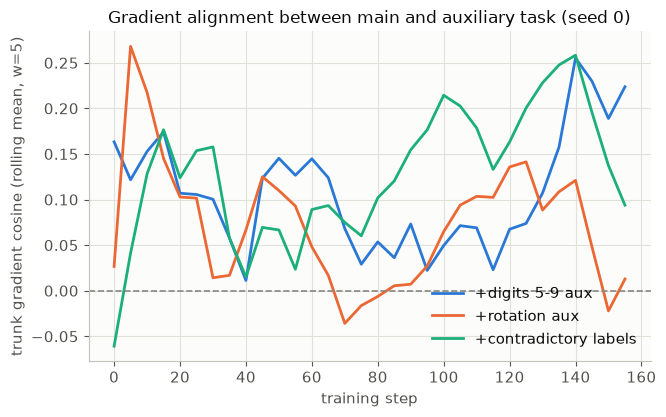

In [4]:
grad_df["cos_smooth"] = (grad_df.groupby("condition")["cos"]
                         .transform(lambda s: s.rolling(5, min_periods=1).mean()))
plt.figure(figsize=(6.8, 4.3))
ax = analysis.plot_curves(grad_df, x="step", y="cos_smooth", hue="condition",
                          marker="",
                          ylabel="trunk gradient cosine (rolling mean, w=5)",
                          title="Gradient alignment between main and auxiliary "
                                "task (seed 0)")
ax.axhline(0.0, color="#898781", linestyle="--", linewidth=1.2)
ax.set_xlabel("training step")
analysis.savefig("05_grad_cosine")

## Takeaways

- **Semantic relatedness is a bad predictor; feature-gradient alignment is
  a good one.** The rotation auxiliary sounds perfectly complementary
  (same images, free labels) — yet it hurts most, and its trunk-gradient
  trace is the lowest of the three. The contradictory-labels auxiliary
  sounds catastrophic — yet its trunk gradients are the *most* aligned
  (same inputs → same feature pressure; the conflict is confined to the
  heads) and it does no harm. The diagnostic ranks the auxiliaries by the
  only conflict that matters, the one inside the shared features — exactly
  Standley et al.'s "measure it, don't assume it" conclusion.
- **Competing invariances are the quiet killer.** Digit identity wants
  orientation-*normalized* features; rotation prediction wants
  orientation-*sensitive* ones. One 128-d embedding cannot fully serve
  both masters, and with only 100 digit labels the 10k-image auxiliary
  wins the tug-of-war. (Notebook 07 shows the same tension from the
  transfer side: rotation-trained final-layer features probe poorly for
  classes.) Interference at MNIST scale is real but worth points, not
  tens of points — consistent with Standley et al.
- **Small conflicts get absorbed.** Contradictory labels on the same 100
  images — adversarial by construction — barely move the needle: a 197k-
  parameter trunk has enough capacity to memorize 100 contradictions in a
  corner of feature space (French 1999's capacity argument, notebook 04's
  forgetting story in reverse). Interference requires *sustained,
  structured* pressure, not just contradiction.
- **Auxiliary learning is a real but delicate lever.** In pilots for this
  notebook, reweighting the rotation loss (0.3–2.0) never turned it
  helpful, while 10k *randomly labeled* fresh images actually helped
  slightly (under-trained memorization of real images degenerates into
  instance discrimination — a weak self-supervised signal). Tiny design
  choices flip the sign of MTL effects at this scale; measure, don't
  assume.

**References.** Caruana, *Multitask Learning* (Machine Learning, 1997).
Ruder, *An Overview of Multi-Task Learning in Deep Neural Networks* (arXiv
2017). Standley et al., *Which Tasks Should Be Learned Together in
Multi-Task Learning?* (ICML 2020). Yu et al., *Gradient Surgery for
Multi-Task Learning* (NeurIPS 2020). French, *Catastrophic forgetting in
connectionist networks* (TiCS 1999).

In [5]:
if not tllab.config.QUICK:
    m = acc_df.groupby("condition")["acc"].mean()
    gc = grad_df.groupby("condition")["cos"].mean()
    analysis.claim("rotation aux interferes (mean <= single - 3 pts)",
                   m["+rotation aux"] <= m["single"] - 0.03,
                   f"{m['+rotation aux']:.3f} vs {m['single']:.3f}", hard=True)
    analysis.claim("trunk gradients more aligned for related aux than rotation aux",
                   gc["+digits 5-9 aux"] > gc["+rotation aux"],
                   f"mean cos {gc['+digits 5-9 aux']:.3f} vs "
                   f"{gc['+rotation aux']:.3f}", hard=True)
    analysis.claim("label-conflict aux aligns on features (cos > rotation aux)",
                   gc["+contradictory labels"] > gc["+rotation aux"],
                   f"mean cos {gc['+contradictory labels']:.3f} vs "
                   f"{gc['+rotation aux']:.3f}", hard=True)
    analysis.claim("related aux helps (mean >= single + 0.5 pt)",
                   m["+digits 5-9 aux"] >= m["single"] + 0.005,
                   f"{m['+digits 5-9 aux']:.3f} vs {m['single']:.3f}")
    analysis.claim("contradiction on 100 images is absorbed (|Δ| < 2 pts)",
                   abs(m["+contradictory labels"] - m["single"]) < 0.02,
                   f"{m['+contradictory labels']:.3f} vs {m['single']:.3f}")

CLAIM CHECK [PASS] rotation aux interferes (mean <= single - 3 pts) — 0.782 vs 0.845
CLAIM CHECK [PASS] trunk gradients more aligned for related aux than rotation aux — mean cos 0.114 vs 0.063
CLAIM CHECK [PASS] label-conflict aux aligns on features (cos > rotation aux) — mean cos 0.129 vs 0.063
CLAIM CHECK [PASS] related aux helps (mean >= single + 0.5 pt) — 0.858 vs 0.845
CLAIM CHECK [PASS] contradiction on 100 images is absorbed (|Δ| < 2 pts) — 0.840 vs 0.845
